# W51 saturated-pixel recovery: v2 training set

2026-10-20

Follows `report_training_set_audit_20261016.ipynb`. The June tables are loaded again for comparison.

In [1]:
import os, sys, glob, re, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from scipy import ndimage
from scipy.stats import spearmanr
from IPython.display import Image, display

REPO = '/blue/adamginsburg/t.yoo/w51_sat_recover'
TRAIN_DIR = '/orange/adamginsburg/w51/TaehwaYoo/w51_sat_recover'
OLD_IMG_DIR = f'{TRAIN_DIR}/cutout_img'
REPORT_IMG_DIR = f'{TRAIN_DIR}/progress_report_img'
PANE_DIR = '/blue/adamginsburg/t.yoo/w51_miri_cal_claude/work'
os.makedirs(REPORT_IMG_DIR, exist_ok=True)
pd.set_option('display.width', 160)

In [2]:
cols = ['flux', 'fluxerr', 'sat_level', 'instrument', 'wavelength', 'dist_to_peak', 'psf_star_flux',
        'DN0', 'DN1', 'DN2', 'DN3', 'DN4', 'nl_strength']
frames = []
for fn in sorted(glob.glob(f'{TRAIN_DIR}/*_ml_training.fits')):
    t = Table.read(fn)
    if len(t) == 0:
        continue
    d = t[cols].to_pandas()
    d['file'] = os.path.basename(fn)
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
df['source_id'] = df['file'] + '|' + df['psf_star_flux'].round(4).astype(str)
df['instrument'] = np.where(df['instrument'] == 0, 'NIRCam', 'MIRI')
print(f'{len(frames)} non-empty tables, {len(df):,} rows, {df.source_id.nunique():,} sources')

471 non-empty tables, 2,048,321 rows, 25,662 sources


## 1. Regenerated training set (v2)

`making_training_set.py` at commit `59fd1d9`, all 15 filters, written to `TRAIN_DIR/v2/`.

* **MIRI** ramps and `cal` files from `/orange/adamginsburg/w51/jwst/jwst_new_cal_claude_satstep/<F>/pipeline_4qpm/`: the `jwst_new_cal_claude` Detector1 settings (`firstframe` and `rscd` skipped, `suppress_one_group=False`) with the `saturation` step on, so saturated groups are left out of the slope fit (`w51_miri_cal_claude/run_report_satstep.ipynb`).
* **NIRCam** from the original `pipeline/` products (default Detector1, `saturation` on).
* Fixes from section 3: per-source labels, `fluxerr` as a standard deviation, `area_ratio` filter.
* New in v2: the label is PSF model + `local_bkg`. `PSFPhotometry` subtracts a local background (`LocalBackground(15, 30)`) before fitting, but the ramp records source plus background. A first v2 run without it gave MIRI label / `cal` medians of 0.60 / 0.40 / 0.28 at `sat_level` 1 / 2 / 3, falling with level as the background share grows; `local_bkg` is now also stored as a column.
* Candidates still come from the `cal` DQ `SATURATED` flag. In the satstep files it matches the ramp `GROUPDQ` for pixels first saturated in groups 0-3 and is never set for group 4 (dropped by `lastframe`), so MIRI has no level-4 rows by construction.

In [17]:
V2 = f'{TRAIN_DIR}/v2'
cols2 = cols + ['x', 'y', 'area_ratio', 'sidelobe_residual_snr', 'local_bkg']
frames = []
for fn in sorted(glob.glob(f'{V2}/*_ml_training.fits')):
    t = Table.read(fn)
    if len(t) == 0:
        continue
    d = t[cols2].to_pandas()
    d['file'] = os.path.basename(fn)
    frames.append(d)
v2 = pd.concat(frames, ignore_index=True)
v2['source_id'] = v2['file'] + '|' + v2['psf_star_flux'].round(4).astype(str)
v2['instrument'] = np.where(v2['instrument'] == 0, 'NIRCam', 'MIRI')
n_tables = len(glob.glob(f'{V2}/*_ml_training.fits'))
print(f'{n_tables} tables ({len(frames)} non-empty), {len(v2):,} rows, {v2.source_id.nunique():,} sources')

480 tables (474 non-empty), 1,179,223 rows, 31,454 sources


In [18]:
def audit_stats(d):
    a = d.groupby('source_id').size()
    return pd.Series({
        'rows': f'{len(d):,}',
        'sources': f'{d.source_id.nunique():,}',
        'dist_to_peak median / max [px]': f'{d.dist_to_peak.median():.1f} / {d.dist_to_peak.max():.0f}',
        'rows within 5 px of fit center': f'{(d.dist_to_peak < 5).mean():.0%}',
        'saturated px per source, median / max': f'{a.median():.0f} / {a.max():,}',
    })

pd.DataFrame({'June run': audit_stats(df), 'v2': audit_stats(v2)})

,June run,v2
rows,"2,048,321","1,179,223"
sources,"25,662","31,454"
dist_to_peak median / max [px],21.7 / 116,2.8 / 65
rows within 5 px of fit center,40%,87%
"saturated px per source, median / max","45 / 11,452","23 / 3,176"


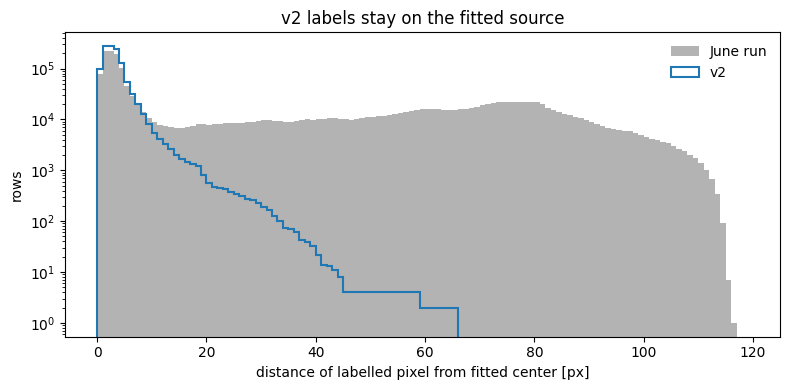

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 120, 1)
ax.hist(df.dist_to_peak, bins=bins, color='0.7', label='June run')
ax.hist(v2.dist_to_peak, bins=bins, color='C0', histtype='step', lw=1.5, label='v2')
ax.set_yscale('log')
ax.set_xlabel('distance of labelled pixel from fitted center [px]')
ax.set_ylabel('rows')
ax.set_title('v2 labels stay on the fitted source')
ax.legend(frameon=False)
plt.tight_layout()

**Why sources were skipped**, counted from the job logs (one warning per skipped source).

In [20]:
logs = sorted(glob.glob(f'{REPO}/script/making_training_set-*_46884*.log'))
reasons = {'HOT pixel': 'flagged as HOT', 'DEAD pixel': 'flagged as DEAD', 'area_ratio': 'larger than the model',
           'fit SNR': 'low SNR', 'faint model': 'pixels above threshold; skipping', 'flux change > 20%': 'changed the total flux',
           'PSF fit failed': 'PSF photometry failed'}
skip = {}
for lf in logs:
    F = re.search(r'making_training_set-(F\w+?)_', lf).group(1)
    txt = open(lf, errors='replace').read()
    row = {'candidates': len(re.findall(r'^Source \d+: center', txt, re.M))}
    row.update({k: txt.count(v) for k, v in reasons.items()})
    row['tracebacks'] = txt.count('Traceback')
    skip[F] = row
skip = pd.DataFrame(skip).T
skip['kept'] = skip['candidates'] - skip[list(reasons)].sum(axis=1)
skip.loc['all'] = skip.sum()
skip

,candidates,HOT pixel,DEAD pixel,area_ratio,fit SNR,faint model,flux change > 20%,PSF fit failed,tracebacks,kept
F1000W,536,63,2,17,106,128,0,137,0,83
F1280W,775,55,7,16,131,312,0,160,0,94
F140M,6133,1371,58,1,88,699,0,0,0,3916
F162M,6855,1390,75,2,87,773,0,0,0,4528
F182M,7845,1401,94,7,53,943,0,0,0,5347
F187N,2821,1363,36,6,46,793,0,0,0,577
F2100W,682,38,2,19,71,350,0,107,0,95
F210M,6437,1394,78,17,56,865,0,0,0,4027
F335M,7478,926,502,152,30,2091,0,0,0,3777
F360M,7020,933,508,123,21,1557,0,0,0,3878


In [21]:
counts2 = pd.crosstab(v2.sat_level, v2.instrument).reindex(columns=['NIRCam', 'MIRI'], fill_value=0)
counts2['sources'] = v2.groupby('sat_level').source_id.nunique()
counts2

instrument,NIRCam,MIRI,sources
sat_level,,,
0,37474,9046,2091
1,423704,10176,9231
2,259404,8638,11296
3,223644,9302,15726
4,197835,0,19642


**Label check against the pipeline slope.** With the `saturation` step on, a pixel that keeps at least 2 unsaturated groups (`sat_level` 2-4) gets its `cal` value from those groups alone, independent of the PSF fit. The ratio PSF-fit label / `cal` value therefore tests the labels where both exist. `sat_level` 1 pixels have a one-group value (MIRI `suppress_one_group=False`), and `sat_level` 0 pixels have no slope.

In [22]:
def cal_path(f):
    base = f.split('_', 1)[1].replace('_ml_training.fits', '_cal.fits')
    F = f.split('_', 1)[0].upper()
    if 'mirimage' in base:
        return f'/orange/adamginsburg/w51/jwst/jwst_new_cal_claude_satstep/{F}/pipeline_4qpm/{base}'
    return f'/orange/adamginsburg/jwst/w51/{F}/pipeline/{base}'

v2['cal_value'] = np.nan
for f, idx in v2.groupby('file').groups.items():
    sci = fits.getdata(cal_path(f), 'SCI')
    sub = v2.loc[idx]
    v2.loc[idx, 'cal_value'] = sci[sub.y.to_numpy(), sub.x.to_numpy()]
v2['label_over_cal'] = v2['flux'] / v2['cal_value']
v2['psf_only_over_cal'] = (v2['flux'] - v2['local_bkg']) / v2['cal_value']
ok = np.isfinite(v2.label_over_cal) & (v2.cal_value > 0)
q = (v2[ok].groupby(['instrument', 'sat_level']).label_over_cal
     .describe(percentiles=[0.16, 0.5, 0.84])[['count', '16%', '50%', '84%']])
q['median without local_bkg'] = v2[ok].groupby(['instrument', 'sat_level']).psf_only_over_cal.median()
q['median local_bkg / cal'] = (v2.local_bkg / v2.cal_value)[ok].groupby([v2.instrument[ok], v2.sat_level[ok]]).median()
q['finite cal / rows'] = (v2.assign(fin=ok).groupby(['instrument', 'sat_level']).fin.mean()).round(2)
q.round(3)

count    16%    50%    84%  median without local_bkg  median local_bkg / cal  finite cal / rows
instrument sat_level                                                                                                    
MIRI       1            9777.0  0.457  0.788  1.078                     0.601                   0.173               0.96
           2            8040.0  0.436  0.739  1.053                     0.404                   0.278               0.93
           3            8091.0  0.500  0.774  1.026                     0.281                   0.397               0.87
NIRCam     0            5504.0  0.922  1.002  1.147                     0.995                   0.005               0.15
           1          415341.0  0.805  1.006  1.240                     0.936                   0.035               0.98
           2          254857.0  0.845  0.990  1.117                     0.885                   0.051               0.98
           3          219765.0  0.856  0.988  1.094                     0.855                   0.076               0.98
           4          194281.0  0.854  0.983  1.083                     0.824                   0.102               0.98

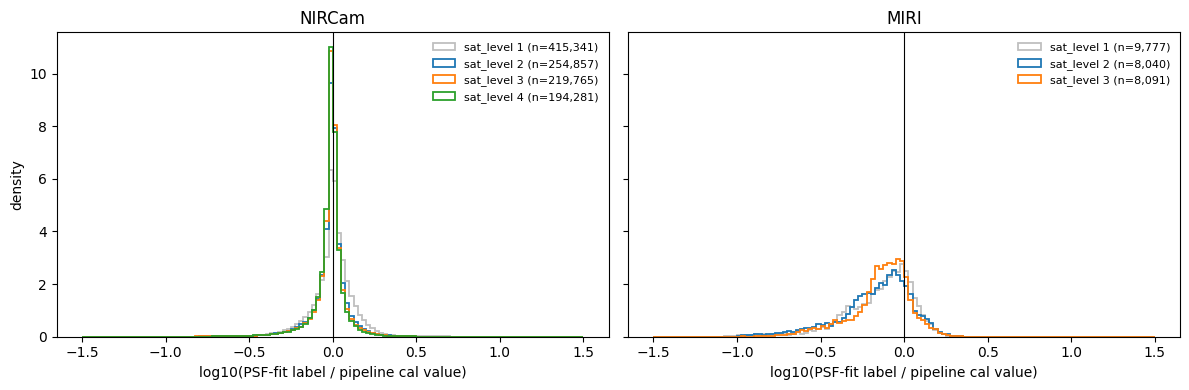

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, inst in zip(axes, ['NIRCam', 'MIRI']):
    for lvl, c in zip([1, 2, 3, 4], ['0.75', 'C0', 'C1', 'C2']):
        r = v2[ok & (v2.instrument == inst) & (v2.sat_level == lvl)].label_over_cal
        if len(r) > 20:
            ax.hist(np.log10(r), bins=np.linspace(-1.5, 1.5, 121), histtype='step', lw=1.3, color=c,
                    label=f'sat_level {lvl} (n={len(r):,})', density=True)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('log10(PSF-fit label / pipeline cal value)')
    ax.set_title(inst)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('density')
plt.tight_layout()

In [24]:
# label / cal against area_ratio, levels 2-4: does the 8.0 cut sit where the labels go bad?
m = ok & v2.sat_level.between(2, 4) & np.isfinite(v2.area_ratio)
bins_ar = [0, 1, 2, 4, 6, 8]
g = v2[m].groupby([v2[m].instrument, pd.cut(v2[m].area_ratio, bins_ar)], observed=True).label_over_cal
g.describe(percentiles=[0.16, 0.5, 0.84])[['count', '16%', '50%', '84%']].round(3)

count    16%    50%    84%
instrument area_ratio                               
MIRI       (0, 1]        1442.0  0.752  0.941  1.071
           (1, 2]        2576.0  0.640  0.874  1.072
           (2, 4]        7806.0  0.358  0.667  0.961
           (4, 6]        2350.0  0.446  0.749  1.006
           (6, 8]        1957.0  0.589  0.778  1.204
NIRCam     (0, 1]      356893.0  0.862  0.992  1.114
           (1, 2]      102481.0  0.849  0.981  1.096
           (2, 4]      119066.0  0.854  0.979  1.082
           (4, 6]       54127.0  0.834  0.970  1.070
           (6, 8]       36336.0  0.805  0.976  1.131

Example diagnostic plots from v2 (the first exposure per detector is plotted).

3852 diagnostic plots


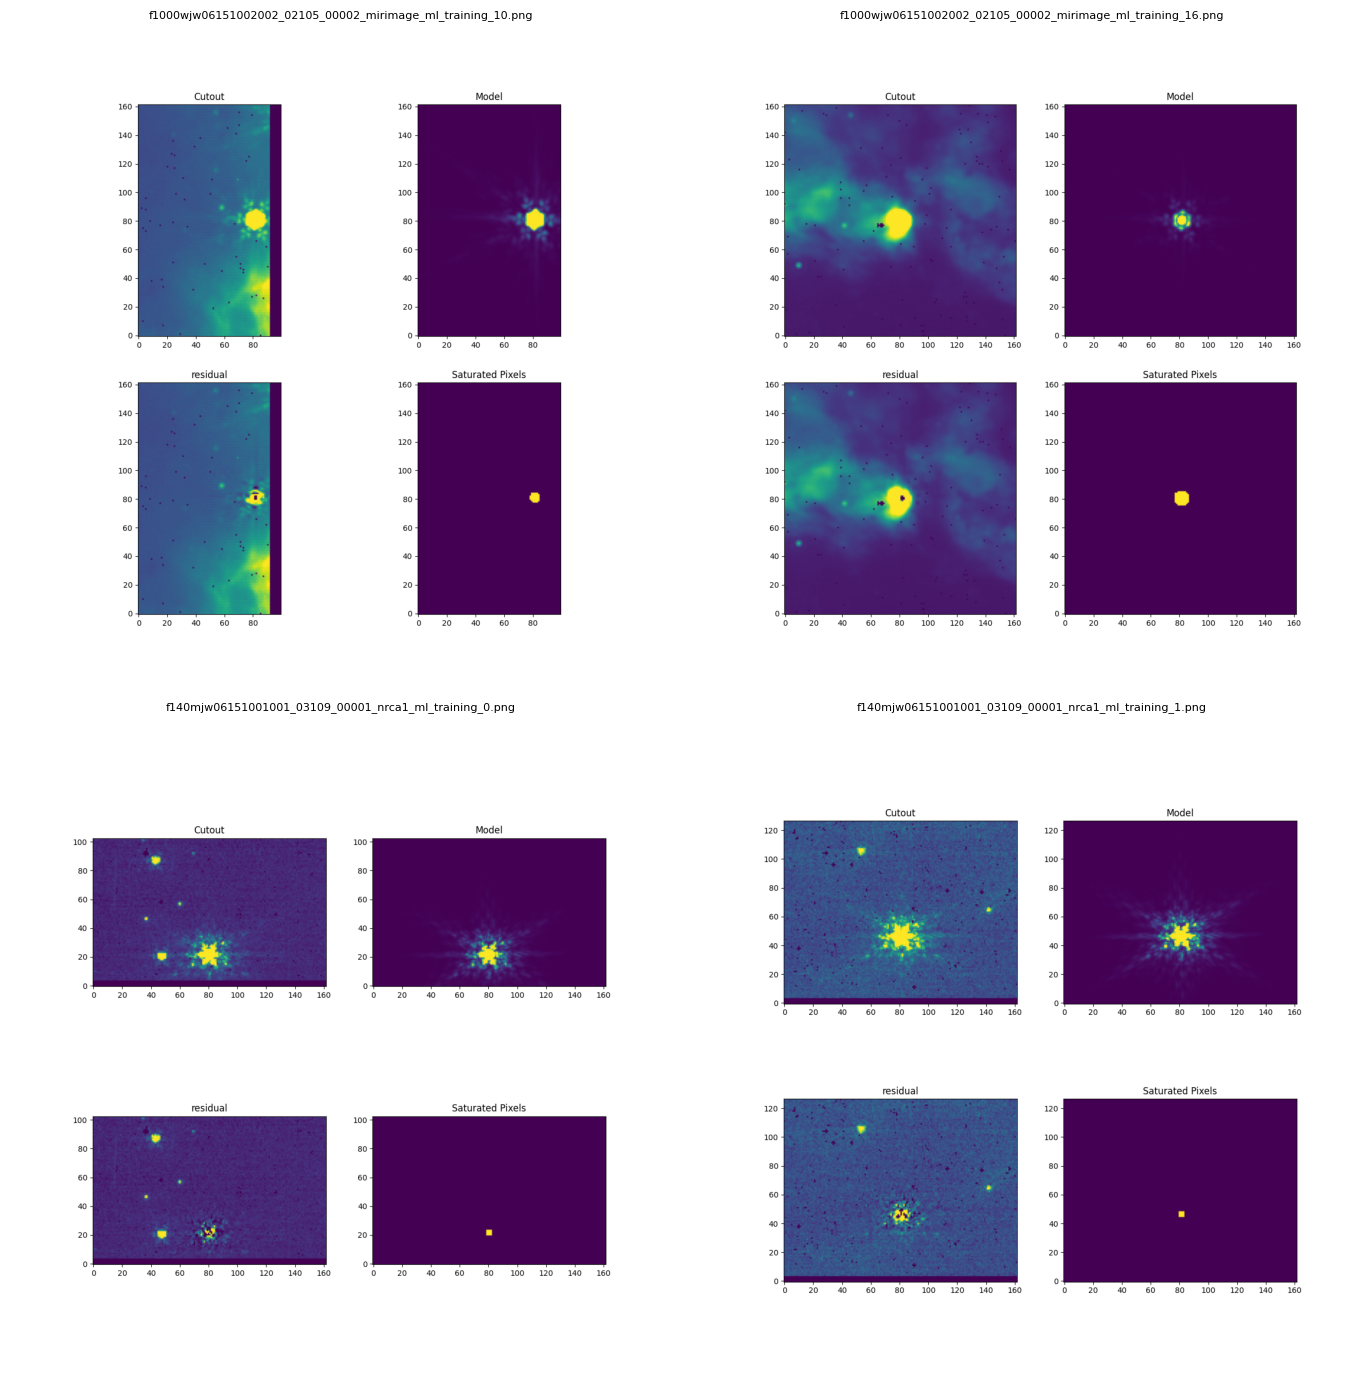

In [25]:
imgs = sorted(glob.glob(f'{V2}/cutout_img/*.png'))
print(len(imgs), 'diagnostic plots')
picks = [p for p in imgs if 'mirimage' in p][:2] + [p for p in imgs if 'nrc' in p][:2]
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, p in zip(axes.flat, picks):
    ax.imshow(plt.imread(p)); ax.set_title(os.path.basename(p), fontsize=8); ax.axis('off')
plt.tight_layout()

**Reading (v2).**

* **Labels stay on the fitted source.** 87% of rows lie within 5 px of the fit center (40% in June), and the largest source has 3,176 saturated pixels (11,452 in June). v2 has 1.18 M rows from 31,454 sources.
* **NIRCam labels agree with the pipeline slope.** Where the slope comes from unsaturated groups, the median PSF-fit label / `cal` value is 0.98-1.01 at every `sat_level`, with a 16-84% range of about +-10-15%. Without `local_bkg` the median falls from 0.94 to 0.82 as the level rises, so adding the background removes that trend.
* **MIRI labels run about 25% low.** The median is 0.74-0.79 at `sat_level` 1-3, with a 16-84% range of 0.44-1.08. The deficit depends on `area_ratio` (median 0.94 at ratio <= 1, 0.67 at 2-4), so it grows for less compact saturated regions. Possible causes, not yet tested: the stpsf MIRI model (the broad wings and cruciform artifact at short wavelengths), the 15-30 px background annulus sitting inside the MIRI PSF wings, and the one-pixel `n_pix_grow_sat` neighbours that the satstep run flags as saturated.
* **Skipped sources.** Of 62,714 candidates, 31,776 are kept. The largest skip reasons are a faint model (14,907) and the HOT-pixel check (11,052, about 18% of candidates). The "flux change > 20%" check never fires: it compares sums over the unsaturated pixels, which the replacement does not change.
* **Class balance.** Level 0 has 46,520 rows (2,091 sources), and MIRI still has no level 4 by construction. MIRI supplies only 1-3% of the rows at each level.


## 2. Next steps

- [x] Commit the `making_training_set.py` and run-script changes
- [x] Choose one Detector1 configuration for MIRI ramps (`jwst_new_cal_claude` settings with `saturation` on)
- [x] Regenerate the training set for all 15 filters
- [x] Find why the PSF-fit table has no MIRI level-4 rows (cal DQ never flags group-4-only saturation)
- [x] Add `local_bkg` to the labels (ramp = source + background)
- [ ] Find the ~25% MIRI label deficit: test the stpsf model, the background annulus size, and `n_pix_grow_sat` neighbours
- [ ] Fix or remove the "flux change > 20%" check (it compares pixels the replacement does not touch)
- [ ] Review diagnostic plots with `area_ratio` between 5 and 10 and adjust the 8.0 threshold
- [ ] Decide how to treat level-0 pixels: drop, down-weight, or keep for NIRCam only
- [ ] Add pane-truth rows for MIRI with a `label_source` column; compare with PSF-fit labels where both exist
- [ ] Check whether the HOT-pixel check is too strict
- [ ] Apply per-source caps and per-level balancing when assembling the gradient-boosting input